# CocoCare — Six-Class Healthy + Disease Classification (MobileNetV3Small)

This notebook builds a new six-class image manifest from the existing raw datasets, removes exact duplicates from the manifest, creates train/validation/test splits, trains MobileNetV3Small, evaluates it, and exports Keras/TFLite models.

**Original raw datasets are never moved, renamed, overwritten or deleted.**

## Data policy
- Five disease classes come from the existing Mendeley dataset.
- Healthy candidates come from Kaggle `Healthy_Leaves`.
- Roboflow healthy candidates are optional and disabled until its class-ID mapping is confirmed from `data.yaml` / README and the images are manually reviewed.
- Do not assume a filename alone proves an image is healthy.
- The 123 Kaggle healthy images are a small class. Results must be interpreted cautiously.
- Exact duplicates are removed. Near-duplicates and same-tree leakage still require review.

## 1. Imports and project paths

In [1]:
from pathlib import Path
from collections import defaultdict
import hashlib, random, json, os, re, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Find ml/ regardless of whether the kernel starts in CocoCare/, ml/, or ml/notebooks/.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
ML_ROOT = None

for base in candidates:
    if base.name == "ml" and (base / "data" / "raw").is_dir():
        ML_ROOT = base
        break
    if (base / "ml" / "data" / "raw").is_dir():
        ML_ROOT = base / "ml"
        break

if ML_ROOT is None:
    raise FileNotFoundError(
        "Could not find CocoCare/ml/data/raw from the current working directory: "
        f"{cwd}. Set ML_ROOT manually."
    )

RAW = ML_ROOT / "data" / "raw"
OUTPUT_ROOT = ML_ROOT / "data" / "processed" / "coconut_health_v2"
SPLIT_ROOT = OUTPUT_ROOT / "splits"
MODEL_ROOT = ML_ROOT / "models" / "coconut_health_v2"
RESULT_ROOT = ML_ROOT / "results" / "coconut_health_v2"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
CLASS_NAMES = [
    "healthy",
    "bud_root_dropping",
    "bud_rot",
    "gray_leaf_spot",
    "leaf_rot",
    "stem_bleeding",
]

print("ML root:", ML_ROOT)
print("Raw:", RAW, "| exists:", RAW.exists())
print("Output:", OUTPUT_ROOT)

ML root: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml
Raw: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw | exists: True
Output: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2


## 2. Configure dataset sources
The folder names below match the inventory you shared. If a folder name differs on disk, update the corresponding path.

In [2]:
MENDELEY_DIR = RAW / "mendeley"
KAGGLE_DIR = RAW / "kaggle"
ROBOFLOW_DIR = RAW / "coconut_leaf_disease_data"

MENDELEY_FOLDER_TO_CLASS = {
    "Bud Root Dropping": "bud_root_dropping",
    "Bud Rot": "bud_rot",
    "Gray Leaf Spot": "gray_leaf_spot",
    "Leaf Rot": "leaf_rot",
    "Stem Bleeding": "stem_bleeding",
}

KAGGLE_HEALTHY_DIR = KAGGLE_DIR / "Healthy_Leaves"

# Optional Roboflow inclusion:
# Your outputs show 123 files with "Healthy" in the filename and annotation class ID 2.
# Enable ONLY after confirming from data.yaml / README that class ID 2 means Healthy,
# and after visually checking the images.
INCLUDE_ROBOFLOW_HEALTHY = False
ROBOFLOW_HEALTHY_CLASS_ID = 2
CONFIRMED_ROBOFLOW_CLASS_ID_IS_HEALTHY = False

for name, path in {
    "Mendeley": MENDELEY_DIR,
    "Kaggle": KAGGLE_DIR,
    "Kaggle Healthy_Leaves": KAGGLE_HEALTHY_DIR,
    "Roboflow": ROBOFLOW_DIR,
}.items():
    print(f"{name:24s}: {path.exists()} | {path}")

if not MENDELEY_DIR.exists():
    raise FileNotFoundError(f"Mendeley folder missing: {MENDELEY_DIR}")
if not KAGGLE_HEALTHY_DIR.exists():
    raise FileNotFoundError(f"Kaggle Healthy_Leaves folder missing: {KAGGLE_HEALTHY_DIR}")

Mendeley                : True | /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw/mendeley
Kaggle                  : True | /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw/kaggle
Kaggle Healthy_Leaves   : True | /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw/kaggle/Healthy_Leaves
Roboflow                : True | /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/raw/coconut_leaf_disease_data


## 3. Build the image manifest
Collect five Mendeley disease classes and the Kaggle Healthy_Leaves folder. Roboflow healthy images are added only after explicit confirmation.

In [3]:
def image_files(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )

rows = []

# Five disease classes from the fixed Mendeley dataset.
for folder_name, class_name in MENDELEY_FOLDER_TO_CLASS.items():
    class_dir = MENDELEY_DIR / folder_name
    files = image_files(class_dir)
    print(f"Mendeley | {folder_name}: {len(files)}")
    for p in files:
        rows.append({
            "path": str(p.resolve()),
            "class_name": class_name,
            "source": "mendeley",
            "source_folder": folder_name,
            "image_type": "leaf_or_disease_image",
        })

# Healthy coconut leaf images from Kaggle.
healthy_files = image_files(KAGGLE_HEALTHY_DIR)
print("Kaggle | Healthy_Leaves:", len(healthy_files))
for p in healthy_files:
    rows.append({
        "path": str(p.resolve()),
        "class_name": "healthy",
        "source": "kaggle",
        "source_folder": "Healthy_Leaves",
        "image_type": "leaf",
    })

# Optional Roboflow images: include only files with healthy-like names AND the confirmed class ID.
if INCLUDE_ROBOFLOW_HEALTHY:
    if not CONFIRMED_ROBOFLOW_CLASS_ID_IS_HEALTHY:
        raise ValueError(
            "Confirm the Roboflow YAML/README class mapping first by setting "
            "CONFIRMED_ROBOFLOW_CLASS_ID_IS_HEALTHY = True."
        )

    added = 0
    for split in ["train", "valid", "test"]:
        img_dir = ROBOFLOW_DIR / split / "images"
        label_dir = ROBOFLOW_DIR / split / "labels"
        for img_path in image_files(img_dir):
            if "healthy" not in img_path.name.lower():
                continue
            label_path = label_dir / f"{img_path.stem}.txt"
            if not label_path.exists():
                continue
            ids = []
            for line in label_path.read_text(errors="replace").splitlines():
                parts = line.strip().split()
                if parts:
                    try:
                        ids.append(int(float(parts[0])))
                    except ValueError:
                        pass
            if ids and all(i == ROBOFLOW_HEALTHY_CLASS_ID for i in ids):
                rows.append({
                    "path": str(img_path.resolve()),
                    "class_name": "healthy",
                    "source": "roboflow",
                    "source_folder": split,
                    "image_type": "leaf",
                })
                added += 1
    print("Roboflow healthy images added:", added)

manifest = pd.DataFrame(rows)
if manifest.empty:
    raise RuntimeError("No images were found. Check dataset folder names.")

print("\nRaw image counts:")
display(manifest.groupby(["source", "class_name"]).size().unstack(fill_value=0))
print("\nTotal candidates:", len(manifest))

Mendeley | Bud Root Dropping: 514
Mendeley | Bud Rot: 470
Mendeley | Gray Leaf Spot: 2135
Mendeley | Leaf Rot: 1673
Mendeley | Stem Bleeding: 1006
Kaggle | Healthy_Leaves: 123

Raw image counts:


class_name,bud_root_dropping,bud_rot,gray_leaf_spot,healthy,leaf_rot,stem_bleeding
source,,,,,,
kaggle,0,0,0,123,0,0
mendeley,514,470,2135,0,1673,1006



Total candidates: 5921


## 4. Validate images and remove exact duplicates
SHA-256 deduplication removes byte-identical copies only. It does not detect visually similar resized/cropped copies.

In [4]:
def sha256_file(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

valid_rows = []
bad_rows = []

for row in manifest.to_dict("records"):
    p = Path(row["path"])
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            width, height = im.size
            if width < 32 or height < 32:
                raise ValueError(f"Image too small: {width}x{height}")
        row["width"] = width
        row["height"] = height
        row["sha256"] = sha256_file(p)
        valid_rows.append(row)
    except Exception as exc:
        bad_rows.append({"path": str(p), "error": str(exc)})

valid_manifest = pd.DataFrame(valid_rows)
bad_manifest = pd.DataFrame(bad_rows)

print("Valid:", len(valid_manifest), "| Invalid:", len(bad_manifest))

# If the same exact image appears in multiple places, retain one copy.
# Prefer the Mendeley disease source for disease labels and Kaggle for healthy.
source_priority = {"mendeley": 0, "kaggle": 1, "roboflow": 2}
valid_manifest["source_priority"] = valid_manifest["source"].map(source_priority).fillna(99)
valid_manifest = valid_manifest.sort_values("source_priority")
dedup_manifest = valid_manifest.drop_duplicates(subset="sha256", keep="first").copy()
dedup_manifest = dedup_manifest.drop(columns=["source_priority"])

print("Removed exact duplicate rows:", len(valid_manifest) - len(dedup_manifest))
display(dedup_manifest.groupby("class_name").size().reindex(CLASS_NAMES, fill_value=0))

Valid: 5921 | Invalid: 0
Removed exact duplicate rows: 34


class_name
healthy               123
bud_root_dropping     514
bud_rot               470
gray_leaf_spot       2103
leaf_rot             1671
stem_bleeding        1006
dtype: int64

## 5. Review class balance and preview samples
Check that the healthy class contains genuinely healthy coconut leaves. Do not include whole-tree images in this leaf-focused experiment unless you intentionally want the classifier to accept both image types.

,images
class_name,
healthy,123
bud_root_dropping,514
bud_rot,470
gray_leaf_spot,2103
leaf_rot,1671
stem_bleeding,1006


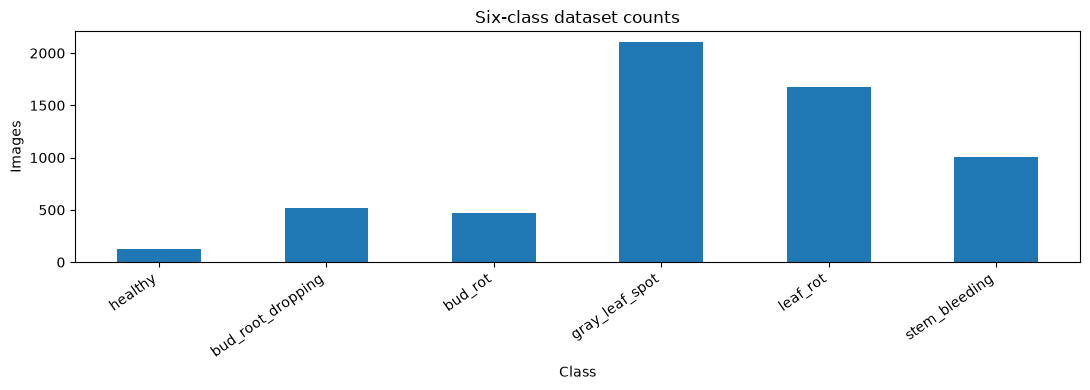

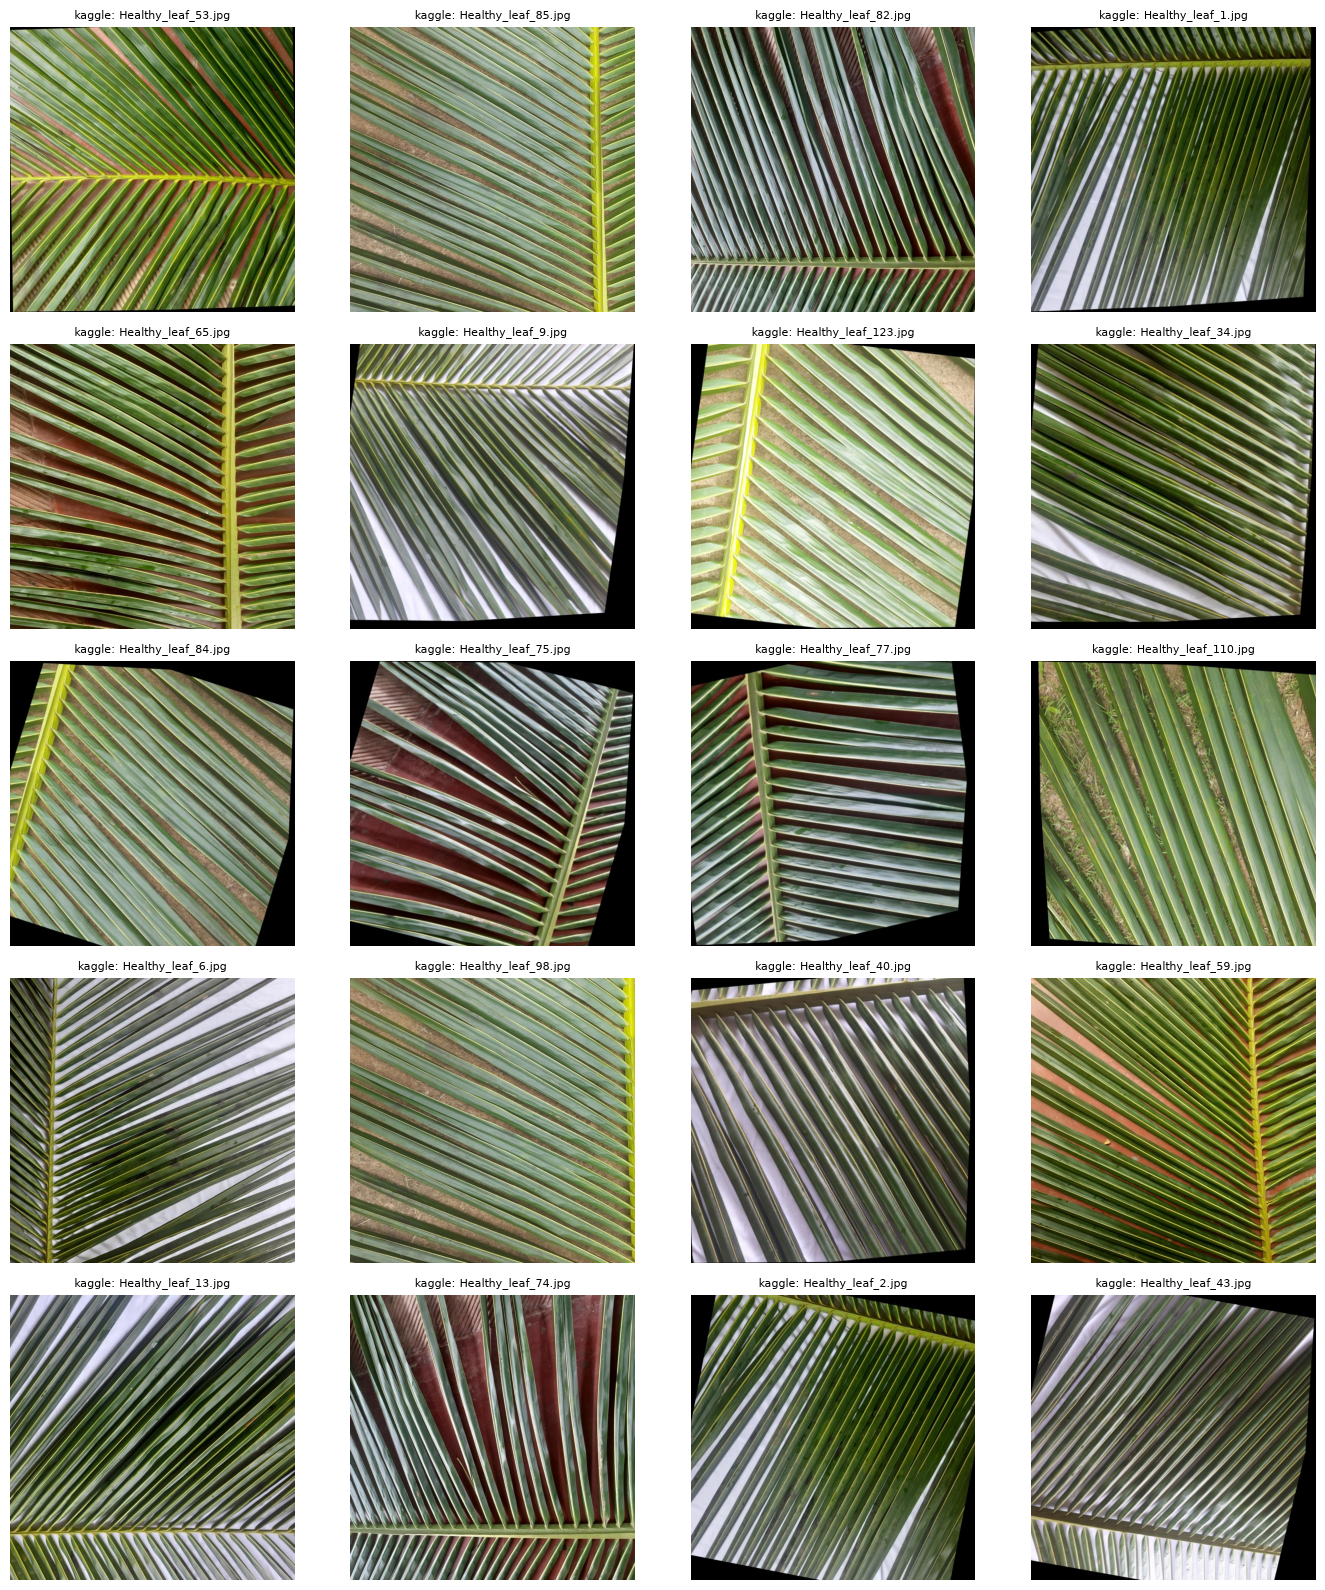

In [5]:
class_counts = dedup_manifest["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0)
display(class_counts.rename("images").to_frame())

ax = class_counts.plot(kind="bar", figsize=(11, 4), title="Six-class dataset counts")
ax.set_ylabel("Images")
ax.set_xlabel("Class")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

def show_samples(df, class_name, n=12):
    subset = df[df.class_name == class_name]
    if subset.empty:
        print("No images for", class_name)
        return
    subset = subset.sample(min(n, len(subset)), random_state=SEED)
    cols = 4
    rows_n = int(np.ceil(len(subset) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(14, rows_n * 3.2))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, (_, row) in zip(axes, subset.iterrows()):
        with Image.open(row.path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f'{row.source}: {Path(row.path).name[:25]}', fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(dedup_manifest, "healthy", n=20)

## 6. Required manual approval

Before training, inspect the healthy preview above. If any healthy candidate is not clearly a coconut leaf / healthy-labelled coconut sample, remove it from `dedup_manifest`.

You may also save a review CSV and edit it manually. The notebook will stop if any of the six classes is empty.

In [6]:
# Export candidate manifest for review and provenance tracking.
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
candidate_csv = OUTPUT_ROOT / "six_class_candidate_manifest.csv"
dedup_manifest.to_csv(candidate_csv, index=False)
print("Candidate manifest:", candidate_csv)

# Training approval: setting this to True records that the healthy samples and source labels
# have been reviewed before creating the fixed experiment splits.
HEALTHY_IMAGES_MANUALLY_REVIEWED = True
print("Healthy-image review approval recorded:", HEALTHY_IMAGES_MANUALLY_REVIEWED)

if not HEALTHY_IMAGES_MANUALLY_REVIEWED:
    raise RuntimeError(
        "Review healthy samples, then set HEALTHY_IMAGES_MANUALLY_REVIEWED = True "
        "to continue. This safeguard prevents unverified labels entering training."
    )

missing = [c for c in CLASS_NAMES if (dedup_manifest.class_name == c).sum() == 0]
if missing:
    raise ValueError(f"Missing classes: {missing}")

Candidate manifest: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2/six_class_candidate_manifest.csv
Healthy-image review approval recorded: True


## 7. Train / validation / test split
Use stratified splitting. Exact duplicates have already been removed. If multiple photos come from the same tree or capture session, group them before splitting; this notebook cannot infer tree identity automatically.

In [7]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    dedup_manifest,
    test_size=0.30,
    random_state=SEED,
    stratify=dedup_manifest["class_name"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["class_name"],
)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"\n{name}: {len(df)}")
    display(df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0))

# Ensure exact hashes do not cross splits.
train_hashes = set(train_df.sha256)
val_hashes = set(val_df.sha256)
test_hashes = set(test_df.sha256)
assert not (train_hashes & val_hashes)
assert not (train_hashes & test_hashes)
assert not (val_hashes & test_hashes)

SPLIT_ROOT.mkdir(parents=True, exist_ok=True)
train_df.to_csv(SPLIT_ROOT / "train.csv", index=False)
val_df.to_csv(SPLIT_ROOT / "validation.csv", index=False)
test_df.to_csv(SPLIT_ROOT / "test.csv", index=False)


train: 4120


class_name
healthy                86
bud_root_dropping     360
bud_rot               329
gray_leaf_spot       1472
leaf_rot             1169
stem_bleeding         704
Name: count, dtype: int64


validation: 883


class_name
healthy               19
bud_root_dropping     77
bud_rot               70
gray_leaf_spot       315
leaf_rot             251
stem_bleeding        151
Name: count, dtype: int64


test: 884


class_name
healthy               18
bud_root_dropping     77
bud_rot               71
gray_leaf_spot       316
leaf_rot             251
stem_bleeding        151
Name: count, dtype: int64

## 8. Install / import TensorFlow and create tf.data pipelines
MobileNetV3Small with `include_preprocessing=True` expects float pixel values in the 0–255 range. Do not rescale to 0–1 a second time.

In [8]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
class_to_index = {name: i for i, name in enumerate(CLASS_NAMES)}
index_to_class = {i: name for name, i in class_to_index.items()}

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Keep 0..255 for MobileNetV3 preprocessing.
    return image, label

def make_dataset(df, training=False):
    paths = df["path"].astype(str).values
    labels = df["class_name"].map(class_to_index).astype("int32").values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

for images, labels in train_ds.take(1):
    print("Batch images:", images.shape, "pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))
    print("Batch labels:", labels[:10].numpy())

I0000 00:00:1793477203.208093   80927 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793477203.361762   80927 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793477204.936664   80927 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
GPUs: []


E0000 00:00:1793477205.206469   80927 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Batch images: (32, 224, 224, 3) pixel range: 0.5526995658874512 255.00009155273438
Batch labels: [4 4 5 3 5 4 4 3 3 3]


## 9. Build MobileNetV3Small

In [9]:
# Data augmentation runs only during training because it is part of the model graph.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

backbone = tf.keras.applications.MobileNetV3Small(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True,
)
backbone.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="image")
x = augmentation(inputs)
x = backbone(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax", name="predictions")(x)

model = tf.keras.Model(inputs, outputs, name="cococare_mobilenetv3small_6class")
model.summary()

print("Total parameters:", model.count_params())
print("Trainable parameters:", sum(int(np.prod(v.shape)) for v in model.trainable_variables))

Model: "cococare_mobilenetv3small_6class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         3,462 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 942,582 (3.60 MB)

 Trainable params: 3,462 (13.52 KB)

 Non-trainable params: 939,120 (3.58 MB)

Total parameters: 942582
Trainable parameters: 3462


## 10. Class weights and Stage 1 feature extraction

In [10]:
y_train = train_df["class_name"].map(class_to_index).values
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=y_train,
)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print("Class weights:", {index_to_class[k]: round(v, 3) for k, v in class_weight.items()})

MODEL_ROOT.mkdir(parents=True, exist_ok=True)
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_ROOT / "stage1_best.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7
    ),
]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

EPOCHS_STAGE1 = 10
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE1,
    class_weight=class_weight,
    callbacks=callbacks,
)

Class weights: {'healthy': 7.984, 'bud_root_dropping': 1.907, 'bud_rot': 2.087, 'gray_leaf_spot': 0.466, 'leaf_rot': 0.587, 'stem_bleeding': 0.975}
Epoch 1/10


/home/sivabharathi/miniconda3/envs/mldlenv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


129/129 ━━━━━━━━━━━━━━━━━━━━ 69s 495ms/step - accuracy: 0.6170 - loss: 0.8705 - val_accuracy: 0.8686 - val_loss: 0.4272 - learning_rate: 0.0010
Epoch 2/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 69s 527ms/step - accuracy: 0.8774 - loss: 0.2921 - val_accuracy: 0.9253 - val_loss: 0.2225 - learning_rate: 0.0010
Epoch 3/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 58s 443ms/step - accuracy: 0.9175 - loss: 0.1962 - val_accuracy: 0.9377 - val_loss: 0.1830 - learning_rate: 0.0010
Epoch 4/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 94s 726ms/step - accuracy: 0.9308 - loss: 0.1588 - val_accuracy: 0.9479 - val_loss: 0.1569 - learning_rate: 0.0010
Epoch 5/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 92s 709ms/step - accuracy: 0.9393 - loss: 0.1289 - val_accuracy: 0.9570 - val_loss: 0.1238 - learning_rate: 0.0010
Epoch 6/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 74s 568ms/step - accuracy: 0.9468 - loss: 0.1136 - val_accuracy: 0.9592 - val_loss: 0.1125 - learning_rate: 0.0010
Epoch 7/10
129/129 ━━━━━━━━━━━━━━━━━━━━ 48s 365ms/step - accuracy: 0.9539 - loss:

## 11. Stage 2 fine-tuning

In [11]:
# Unfreeze the backbone, but keep BatchNormalization layers frozen.
backbone.trainable = True
for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Fine-tune only the last 30 backbone layers (excluding frozen BN layers).
for layer in backbone.layers[:-30]:
    layer.trainable = False

print("Trainable backbone layers:",
      sum(1 for layer in backbone.layers if layer.trainable))
print("Total model trainable variables:",
      sum(int(np.prod(v.shape)) for v in model.trainable_variables))

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_ROOT / "stage2_best.keras"),
        monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.2, patience=2, min_lr=1e-8
    ),
]

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

EPOCHS_STAGE2 = 15
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_STAGE2,
    class_weight=class_weight,
    callbacks=callbacks_stage2,
)

Trainable backbone layers: 24
Total model trainable variables: 586662
Epoch 1/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 71s 512ms/step - accuracy: 0.9680 - loss: 0.0667 - val_accuracy: 0.9751 - val_loss: 0.0622 - learning_rate: 1.0000e-05
Epoch 2/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 66s 503ms/step - accuracy: 0.9745 - loss: 0.0543 - val_accuracy: 0.9785 - val_loss: 0.0596 - learning_rate: 1.0000e-05
Epoch 3/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 67s 511ms/step - accuracy: 0.9728 - loss: 0.0483 - val_accuracy: 0.9785 - val_loss: 0.0548 - learning_rate: 1.0000e-05
Epoch 4/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 58s 445ms/step - accuracy: 0.9735 - loss: 0.0455 - val_accuracy: 0.9785 - val_loss: 0.0502 - learning_rate: 1.0000e-05
Epoch 5/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 66s 508ms/step - accuracy: 0.9779 - loss: 0.0413 - val_accuracy: 0.9864 - val_loss: 0.0433 - learning_rate: 1.0000e-05
Epoch 6/15
129/129 ━━━━━━━━━━━━━━━━━━━━ 61s 468ms/step - accuracy: 0.9825 - loss: 0.0376 - val_accuracy: 0.9864 - val_loss: 0.0441 - le

## 12. Select the best validation checkpoint and evaluate the test set once

Stage 1 validation loss: 0.07309181243181229
Stage 2 validation loss: 0.023389969021081924
Selected: Stage 2
28/28 ━━━━━━━━━━━━━━━━━━━━ 8s 263ms/step - accuracy: 0.9955 - loss: 0.0302
Test loss: 0.0302
Test accuracy: 99.5475%
28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 366ms/step
                   precision    recall  f1-score   support

          healthy       1.00      1.00      1.00        18
bud_root_dropping       1.00      1.00      1.00        77
          bud_rot       0.99      0.99      0.99        71
   gray_leaf_spot       0.99      1.00      1.00       316
         leaf_rot       1.00      0.99      0.99       251
    stem_bleeding       1.00      1.00      1.00       151

         accuracy                           1.00       884
        macro avg       1.00      1.00      1.00       884
     weighted avg       1.00      1.00      1.00       884



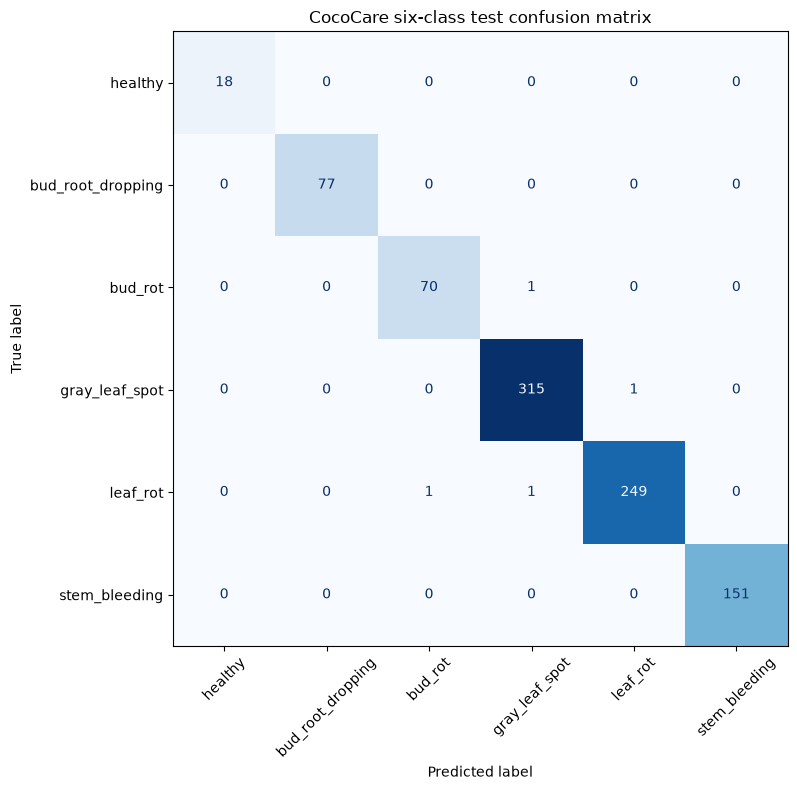

In [12]:
# Compare validation loss from the two saved stages; test set is not used for model selection.
stage1_model = tf.keras.models.load_model(MODEL_ROOT / "stage1_best.keras")
stage2_model = tf.keras.models.load_model(MODEL_ROOT / "stage2_best.keras")

stage1_val_loss = stage1_model.evaluate(val_ds, verbose=0)[0]
stage2_val_loss = stage2_model.evaluate(val_ds, verbose=0)[0]
print("Stage 1 validation loss:", stage1_val_loss)
print("Stage 2 validation loss:", stage2_val_loss)

best_model = stage2_model if stage2_val_loss <= stage1_val_loss else stage1_model
print("Selected:", "Stage 2" if best_model is stage2_model else "Stage 1")

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true, y_pred,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("CocoCare six-class test confusion matrix")
plt.tight_layout()
plt.show()

## 13. Save model, class labels, metadata and TFLite

In [13]:
best_model.save(MODEL_ROOT / "cococare_mobilenetv3small_6class.keras")

with open(MODEL_ROOT / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

metadata = {
    "architecture": "MobileNetV3Small",
    "input_shape": [224, 224, 3],
    "classes": CLASS_NAMES,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "train_images": int(len(train_df)),
    "validation_images": int(len(val_df)),
    "test_images": int(len(test_df)),
    "sources": sorted(dedup_manifest["source"].unique().tolist()),
    "note": "Healthy class requires manual label verification; exact duplicates removed.",
}
with open(MODEL_ROOT / "training_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
tflite_model = converter.convert()
tflite_path = MODEL_ROOT / "cococare_mobilenetv3small_6class.tflite"
tflite_path.write_bytes(tflite_model)

print("Saved Keras model:", MODEL_ROOT / "cococare_mobilenetv3small_6class.keras")
print("Saved TFLite model:", tflite_path)
print("TFLite size (MB):", round(tflite_path.stat().st_size / (1024**2), 2))

INFO:tensorflow:Assets written to: /tmp/tmp22xcabjl/assets


INFO:tensorflow:Assets written to: /tmp/tmp22xcabjl/assets


Saved artifact at '/tmp/tmp22xcabjl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  124771021269584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021273424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021273232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021272848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021274000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021270544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021273616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021274384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021271504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021274960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124771021273808: Tens

W0000 00:00:1793478887.147880   80927 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793478887.147913   80927 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793478887.149667   80927 reader.cc:83] Reading SavedModel from: /tmp/tmp22xcabjl
I0000 00:00:1793478887.170233   80927 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793478887.170269   80927 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp22xcabjl
I0000 00:00:1793478887.245530   80927 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793478887.258285   80927 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793478887.705846   80927 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp22xcabjl
I0000 00:00:1793478887.876691   80927 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 727039 microseconds.
I0000 00:00:1793478888.041827   8092

## 14. Export the final manifests and experiment summary

Keep the train/validation/test CSV files with the model so the experiment is reproducible. Record the source licences and citations separately in your project documentation.

In [14]:
dedup_manifest.to_csv(OUTPUT_ROOT / "all_six_class_images.csv", index=False)

summary = {
    "class_counts": class_counts.to_dict(),
    "split_counts": {
        "train": train_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict(),
        "validation": val_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict(),
        "test": test_df["class_name"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict(),
    },
    "duplicates_removed": int(len(valid_manifest) - len(dedup_manifest)),
    "invalid_images": int(len(bad_manifest)),
}
with open(OUTPUT_ROOT / "dataset_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Dataset summary:", OUTPUT_ROOT / "dataset_summary.json")
print("Model artifacts:", MODEL_ROOT)

Dataset summary: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/data/processed/coconut_health_v2/dataset_summary.json
Model artifacts: /run/media/sivabharathi/ssd/storage/finalYear/CocoCare/ml/models/coconut_health_v2
